In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

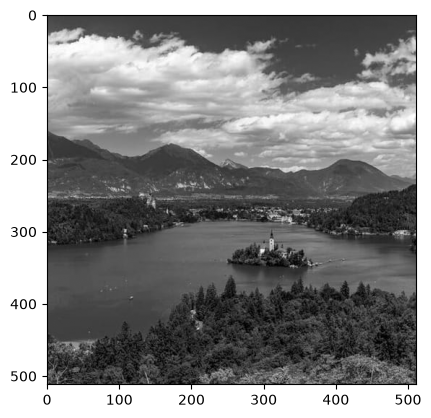

In [2]:
image = cv2.imread('image.jpg', cv2.IMREAD_GRAYSCALE)
plt.imshow(image, cmap='gray')

In [30]:
def haar(image, levels):
    coeffs = image.astype(np.float32)
    for level in range(levels):
        n = coeffs.shape[0] >> level
        b = coeffs[:n, :n]
        b = np.hstack(((b[:, 0::2] + b[:, 1::2]) / 2, (b[:, 0::2] - b[:, 1::2]) / 2))
        coeffs[:n, :n] = np.vstack(((b[0::2] + b[1::2]) / 2, (b[0::2] - b[1::2]) / 2))
    return coeffs

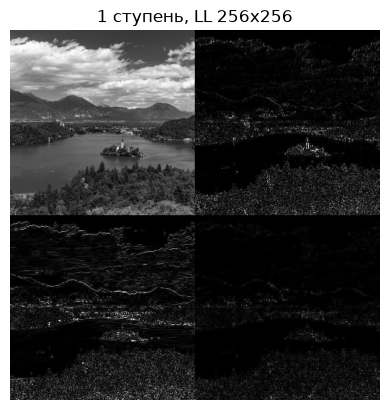

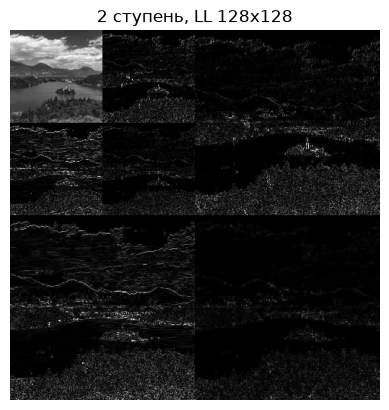

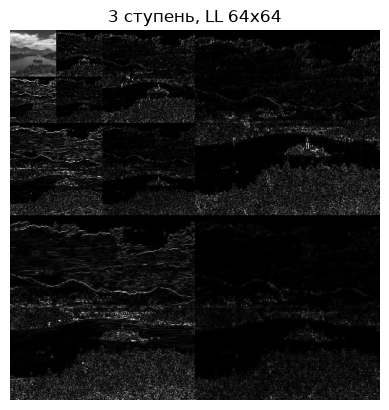

In [31]:
for level in range(1, 4):
    coeffs = haar(image, level)
    vis = np.clip(np.abs(coeffs) * 5, 0, 255)
    n = 512 >> level
    vis[:n, :n] = coeffs[:n, :n]
    
    plt.imshow(vis, cmap='gray')
    plt.title(str(level) + ' ступень, LL ' + str(n) + 'x' + str(n)), plt.axis('off')
    plt.show()